In [ ]:
'''
Script that takes the paths for the original spreadsheet, the folder with the train set and the folder with the validation set
and produces a new spreadsheet with additional columns with properties of the images comprising the dataset.

For a preliminary analysis of a dataset intended for object detection it's important to focus on properties that provide insights into the dataset's characteristics and variability, without delving too deeply into complex feature extractions.
We look into the following properties:
- Image Dimensions: Width and height of each image. This helps to understand the size distribution of the images and whether any resizing or normalization is needed.
- Aspect Ratio: The ratio of width to height. This can be important for understanding how much variation there is in the shapes of the images.
- Color Distribution: Basic color analysis based on the average intensity per channel (Red, Green, Blue).
- Contrast and Brightness: Basic statistics on the brightness and contrast of the images can be useful to assess the need for pre-processing steps like contrast normalization.
- Presence of Blurriness assessed using the variance of the Laplacian.
'''

In [1]:
import cv2
import pandas as pd
import numpy as np
import tkinter as tk
from tkinter import filedialog
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os

In [2]:
# Open file dialog to select the spreadsheet file
spreadsheet_path = filedialog.askopenfilename(
    title="Select the Spreadsheet File",
    filetypes=[("Excel files", "*.xlsx")]
)
    
# Open directory dialogs to select train and validation folders
train_folder_path = filedialog.askdirectory(title="Select Train Set Folder")
validation_folder_path = filedialog.askdirectory(title="Select Validation Set Folder")

In [3]:
# Function to calculate image properties
def get_image_properties(image_path):
    image = cv2.imread(image_path)
    height, width, channels = image.shape

    # Calculating aspect ratio
    aspect_ratio = width / height if height != 0 else 0

    # Calculating average intensity per channel (Red, Green, Blue)
    avg_intensity_per_channel = np.mean(image, axis=(0, 1))
    avg_red_intensity = avg_intensity_per_channel[0]
    avg_green_intensity = avg_intensity_per_channel[1]
    avg_blue_intensity = avg_intensity_per_channel[2]

    # Calculating brightness and contrast
    brightness = np.mean(avg_intensity_per_channel)
    contrast = np.std(image)

    # Blurriness
    laplacian_var = cv2.Laplacian(image, cv2.CV_64F).var()

    return width, height, aspect_ratio, avg_red_intensity, avg_green_intensity, avg_blue_intensity, brightness, contrast, laplacian_var

# Main function to update the spreadsheet with image properties
def update_spreadsheet_with_image_properties(spreadsheet_p, train_folder_p, validation_folder_p):
    
    # Load the spreadsheet
    root = tk.Tk()
    root.withdraw()  # Hide the main window
    
    if not (spreadsheet_p and train_folder_p and validation_folder_p):
        return "File paths must be provided."

    # Read the spreadsheet
    spreadsheet = pd.ExcelFile(spreadsheet_p)

    # Process Train Set
    train_df = pd.read_excel(spreadsheet, 'train_set')
    train_df[['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 'Avg Green Intensity', 
              'Avg Blue Intensity', 'Brightness', 'Contrast', 'Blurriness']] = None

    for idx, row in train_df.iterrows():
        patient_folder = os.path.join(train_folder_p, row['PATIENT_ID'])
        polyp_folder = os.path.join(patient_folder, row['POLYP_ID'])
        image_p = os.path.join(polyp_folder, row['IMG_FILE_PREFIX'] + ".full.png")
        if os.path.exists(image_p):
            properties = get_image_properties(image_p)
            train_df.loc[idx, ['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 
                           'Avg Green Intensity', 'Avg Blue Intensity', 'Brightness', 
                           'Contrast', 'Blurriness']] = properties
    
    # Process Validation Set
    validation_df = pd.read_excel(spreadsheet, 'validation_set')
    validation_df[['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 'Avg Green Intensity', 
                   'Avg Blue Intensity', 'Brightness', 'Contrast', 'Blurriness']] = None

    for idx, row in validation_df.iterrows():
        patient_folder = os.path.join(validation_folder_p, row['PATIENT_ID'])
        image_id = row['POLYP/IMAGE_ID']
        image_p = os.path.join(patient_folder, image_id + ".png")

        if os.path.exists(image_p):
            properties = get_image_properties(image_p)
            validation_df.loc[idx, ['Width', 'Height', 'Aspect Ratio', 'Avg Red Intensity', 
                           'Avg Green Intensity', 'Avg Blue Intensity', 'Brightness', 
                           'Contrast', 'Blurriness']] = properties
    # Save the updated spreadsheets
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    new_spreadsheet_p = spreadsheet_p.replace('.xlsx', f'_{timestamp}.xlsx')
    with pd.ExcelWriter(new_spreadsheet_p) as writer:
        train_df.to_excel(writer, sheet_name='train_set', index=False)
        validation_df.to_excel(writer, sheet_name='validation_set', index=False)
    return new_spreadsheet_p

# Call the function with placeholder paths (to be replaced with actual paths)
spreadsheet_with_image_properties_path = update_spreadsheet_with_image_properties(spreadsheet_path, train_folder_path, validation_folder_path)
print(f"Updated spreadsheet saved as {spreadsheet_with_image_properties_path}")

Updated spreadsheet saved as /Users/irconde/Downloads/Databases/POLAR/polar_public/polar_annotations_20231125192143.xlsx


In [ ]:
# Load the Excel file containing the POLAR dataset with the annotations and image properties

In [ ]:
spreadsheet_with_image_properties_path = filedialog.askopenfilename(
        title="Select the Spreadsheet File",
        filetypes=[("Excel files", "*.xlsx")]
    )

In [ ]:
# Fields in each sheet (book) in the spreadsheet

In [4]:
# Load both sheets separately
train_set = pd.read_excel(spreadsheet_with_image_properties_path, sheet_name='train_set')
validation_set = pd.read_excel(spreadsheet_with_image_properties_path, sheet_name='validation_set')

# Display the column names for both the training and validation sets
columns_train = train_set.columns
columns_validation = validation_set.columns

columns_train, columns_validation

(Index(['PATIENT_ID', 'POLYP_ID', 'IMG_FILE_PREFIX', 'POLYP POSITION (x,y,w,h)',
        'SIZE', 'PATHOLOGY DIAGNOSIS', 'Width', 'Height', 'Aspect Ratio',
        'Avg Red Intensity', 'Avg Green Intensity', 'Avg Blue Intensity',
        'Brightness', 'Contrast', 'Blurriness'],
       dtype='object'),
 Index(['PATIENT_ID', 'POLYP/IMAGE_ID', 'POLYP POSITION (x,y,w,h)',
        'POLYP MORPHOLOGY', 'POLYP SIZE', 'POLYP LOCATION', 'OPTICAL DIAGNOSIS',
        'OPTCAL DIAGNOSIS CONFIDENCE', 'PATHOLOGY DIAGNOSIS', 'Width', 'Height',
        'Aspect Ratio', 'Avg Red Intensity', 'Avg Green Intensity',
        'Avg Blue Intensity', 'Brightness', 'Contrast', 'Blurriness'],
       dtype='object'))

In [ ]:
# Calculate the number of entries in each sheet

In [5]:
num_entries_train = train_set.shape[0]
num_entries_validation = validation_set.shape[0]

num_entries_train, num_entries_validation

(2637, 730)

In [ ]:
# Number of unique polyps and patients

In [6]:
unique_polyps_train = train_set['POLYP_ID'].nunique()
unique_patients_train = train_set['PATIENT_ID'].nunique()
unique_polyps_validation = validation_set['POLYP/IMAGE_ID'].nunique()
unique_patients_validation = validation_set['PATIENT_ID'].nunique()

unique_polyps_train, unique_patients_train, unique_polyps_validation, unique_patients_validation

(1339, 555, 730, 251)

In [ ]:
# Number of polyps per image

In [7]:
# Count the number of polyps per image in the training set
polyps_per_image_train = train_set.groupby('IMG_FILE_PREFIX')['POLYP_ID'].nunique()

# Count the number of polyps per image in the validation set, using the correct column name for polyp identification
polyps_per_image_validation = validation_set.groupby('POLYP/IMAGE_ID')['POLYP/IMAGE_ID'].nunique()

# Calculate the average number of polyps per image for both sets
avg_polyps_per_image_train = polyps_per_image_train.mean()
avg_polyps_per_image_validation = polyps_per_image_validation.mean()

avg_polyps_per_image_train, avg_polyps_per_image_validation, polyps_per_image_train.describe(), polyps_per_image_validation.describe()


(1.0,
 1.0,
 count    2637.0
 mean        1.0
 std         0.0
 min         1.0
 25%         1.0
 50%         1.0
 75%         1.0
 max         1.0
 Name: POLYP_ID, dtype: float64,
 count    730.0
 mean       1.0
 std        0.0
 min        1.0
 25%        1.0
 50%        1.0
 75%        1.0
 max        1.0
 Name: POLYP/IMAGE_ID, dtype: float64)

In [ ]:
# Distribution of polyp sizes. Figures

In [8]:
# Calculate the distribution of polyps by size for the training set
size_distribution_train = train_set['SIZE'].value_counts()

# Calculate the distribution of polyps by size for the validation set
size_distribution_validation = validation_set['POLYP SIZE'].value_counts()

size_distribution_train, size_distribution_validation

(SIZE
 -1    1116
  2     403
  3     325
  4     236
  1     185
  5     146
  6      90
  8      54
  7      40
  0      38
  9       4
 Name: count, dtype: int64,
 POLYP SIZE
  3     165
  2     120
  5      93
  4      85
  6      39
  10     38
  8      35
  7      33
  15     24
  12     20
  1      18
  20     18
  30      9
  25      6
  40      6
  9       5
  18      4
  13      3
  11      2
 -95      2
  22      1
  35      1
  21      1
  14      1
  50      1
 Name: count, dtype: int64)

In [ ]:
# Distribution of polyp sizes. Histogram (negative values excluded)

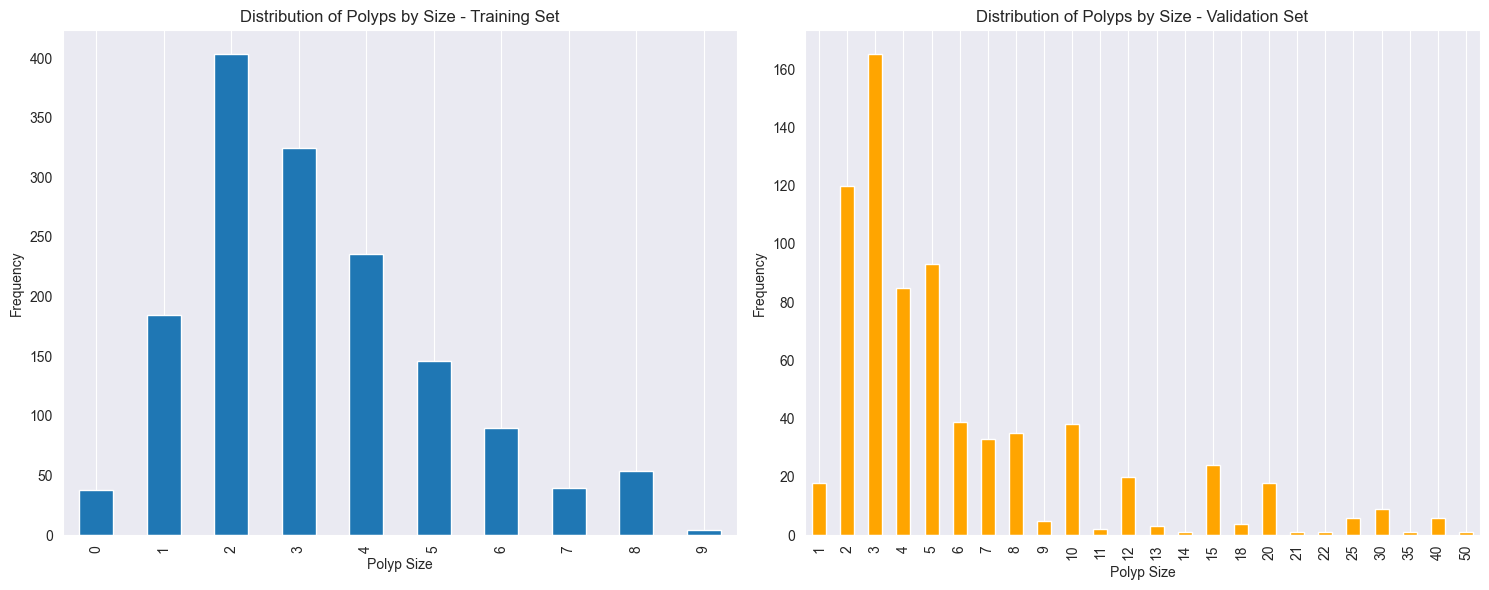

In [9]:
# Remove entries with negative values from the size columns for both sets
train_set_filtered = train_set[train_set['SIZE'] >= 0]
validation_set_filtered = validation_set[validation_set['POLYP SIZE'] >= 0]

# Recalculate the distribution of polyps by size for the filtered data
size_distribution_train_filtered = train_set_filtered['SIZE'].value_counts().sort_index()
size_distribution_validation_filtered = validation_set_filtered['POLYP SIZE'].value_counts().sort_index()

# Plot histograms for the distribution of polyps by size for both sets
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
size_distribution_train_filtered.plot(kind='bar')
plt.title('Distribution of Polyps by Size - Training Set')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')

plt.subplot(1, 2, 2)
size_distribution_validation_filtered.plot(kind='bar', color='orange')
plt.title('Distribution of Polyps by Size - Validation Set')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# Distribution of polyp sizes. Descriptive statistics (excluding negative values)

In [10]:
# Extracting only the descriptive statistics for the polyp size in both sets
desc_stats_size_train = train_set_filtered['SIZE'].describe()
desc_stats_size_validation = validation_set_filtered['POLYP SIZE'].describe()

desc_stats_size_train, desc_stats_size_validation

(count    1521.000000
 mean        3.239974
 std         1.842733
 min         0.000000
 25%         2.000000
 50%         3.000000
 75%         4.000000
 max         9.000000
 Name: SIZE, dtype: float64,
 count    728.000000
 mean       6.350275
 std        6.380602
 min        1.000000
 25%        3.000000
 50%        4.000000
 75%        7.000000
 max       50.000000
 Name: POLYP SIZE, dtype: float64)

In [ ]:
# Distribution of polyp sizes. Box plot

<Figure size 800x600 with 0 Axes>

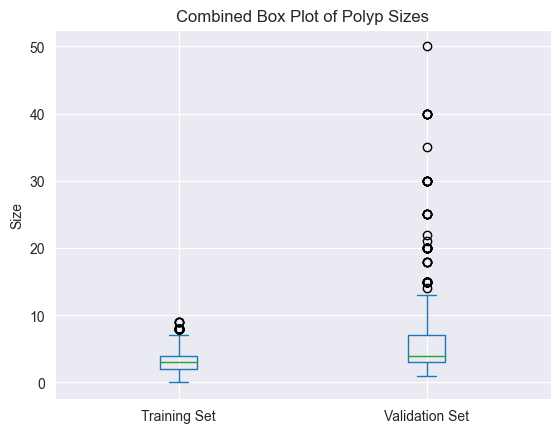

In [11]:
# Combine both training and validation sets into one DataFrame for a combined box plot
combined_sizes = pd.DataFrame({
    'Training Set': train_set_filtered['SIZE'],
    'Validation Set': validation_set_filtered['POLYP SIZE']
})

# Generate a combined vertical box plot for both sets
plt.figure(figsize=(8, 6))
combined_sizes.plot(kind='box')
plt.title('Combined Box Plot of Polyp Sizes')
plt.ylabel('Size')
plt.grid(True)
plt.show()

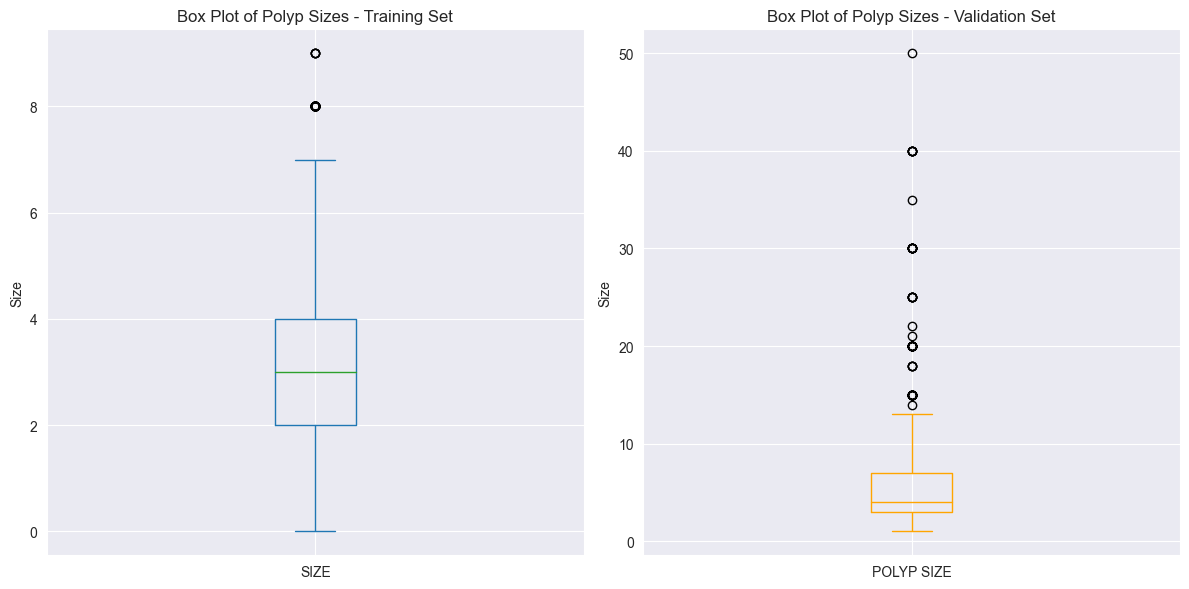

In [12]:
# Generate vertical box plots for the polyp sizes in the training and validation sets
plt.figure(figsize=(12, 6))

# Vertical box plot for the training set
plt.subplot(1, 2, 1)
train_set_filtered['SIZE'].plot(kind='box')
plt.title('Box Plot of Polyp Sizes - Training Set')
plt.ylabel('Size')

# Vertical box plot for the validation set
plt.subplot(1, 2, 2)
validation_set_filtered['POLYP SIZE'].plot(kind='box', color='orange')
plt.title('Box Plot of Polyp Sizes - Validation Set')
plt.ylabel('Size')

plt.tight_layout()
plt.show()

In [ ]:
# Distribution of polyp sizes. Train and validation sets together

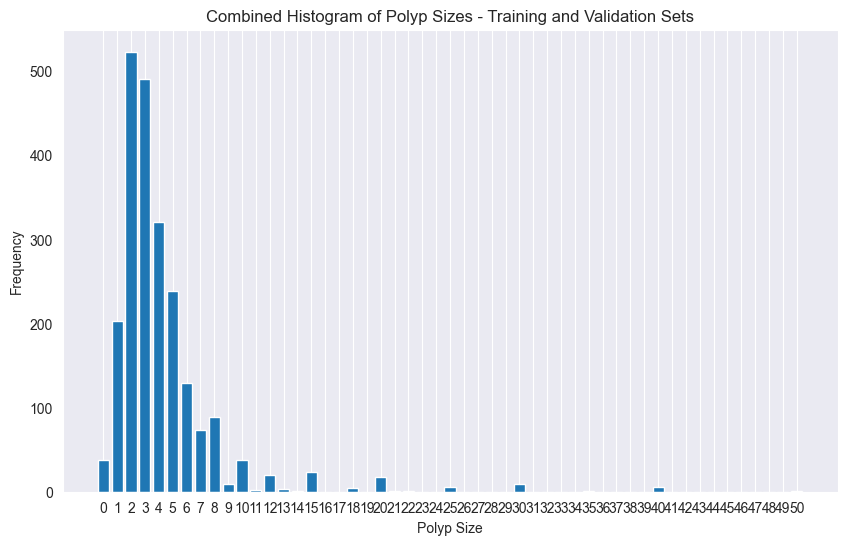

In [13]:
# Combine the polyp size data from both sets for a combined distribution analysis
combined_sizes_distribution = pd.concat([train_set_filtered['SIZE'], validation_set_filtered['POLYP SIZE']], ignore_index=True)

# Plot the histogram for the combined polyp size distribution
plt.figure(figsize=(10, 6))
combined_sizes_distribution.hist(bins=range(int(combined_sizes_distribution.max()) + 2), rwidth=0.8, align='left')
plt.title('Combined Histogram of Polyp Sizes - Training and Validation Sets')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')
plt.xticks(range(int(combined_sizes_distribution.max()) + 1))
plt.show()

In [ ]:
# Distribution of polyp sizes based on the different ranges considered by the authors: Diminutive Polyps (1-5 mm), Small Polyps (6-9 mm), Larger Polyps (>=10 mm)

SIZE
Diminutive (1-5 mm)    1295
Small (6-9 mm)          188
Larger (>=10 mm)          0
Name: count, dtype: int64 POLYP SIZE
Diminutive (1-5 mm)    481
Small (6-9 mm)         112
Larger (>=10 mm)       135
Name: count, dtype: int64


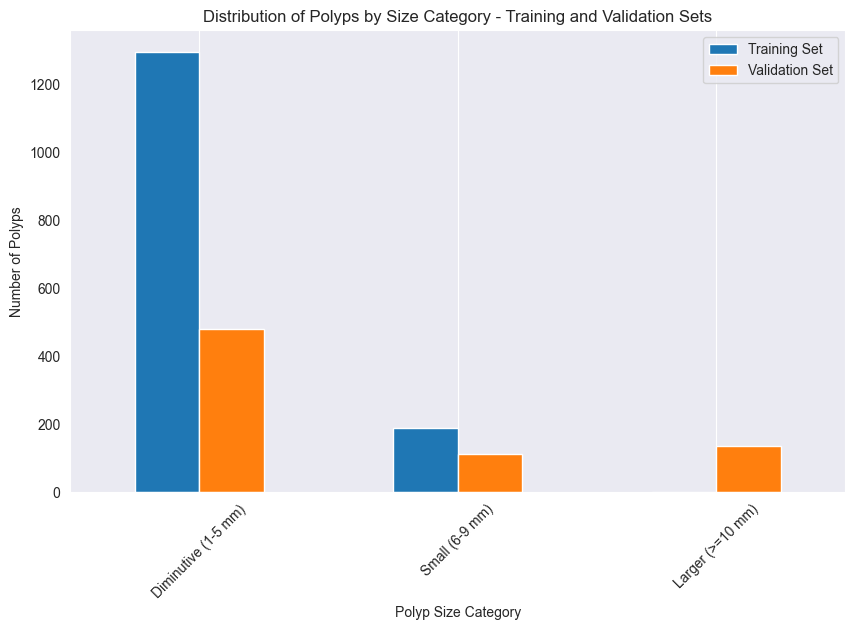

In [14]:
# Categorize polyp sizes into three groups for the training set
size_categories_train = pd.cut(train_set_filtered['SIZE'], bins=[0, 5, 9, float('inf')], labels=['Diminutive (1-5 mm)', 'Small (6-9 mm)', 'Larger (>=10 mm)'])

# Calculate the distribution of polyps by these size categories in the training set
size_category_distribution_train = size_categories_train.value_counts().sort_index()

# Categorize polyp sizes into three groups for the validation set
size_categories_validation = pd.cut(validation_set_filtered['POLYP SIZE'], bins=[0, 5, 9, float('inf')], labels=['Diminutive (1-5 mm)', 'Small (6-9 mm)', 'Larger (>=10 mm)'])

# Calculate the distribution of polyps by these size categories in the validation set
size_category_distribution_validation = size_categories_validation.value_counts().sort_index()

print(size_category_distribution_train, size_category_distribution_validation)

# Prepare data for bar chart
size_category_distribution_combined = pd.DataFrame({
    'Training Set': size_category_distribution_train,
    'Validation Set': size_category_distribution_validation
})

# Generate a bar chart for the distribution of polyp sizes in the training and validation sets
size_category_distribution_combined.plot(kind='bar', figsize=(10, 6))
plt.title('Distribution of Polyps by Size Category - Training and Validation Sets')
plt.xlabel('Polyp Size Category')
plt.ylabel('Number of Polyps')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


In [ ]:
# Distribution of polyp sizes based on the different ranges considered by the authors: Diminutive Polyps (1-5 mm), Small Polyps (6-9 mm), Larger Polyps (>=10 mm). Train and validation sets together

Diminutive (1-5 mm)    1776
Small (6-9 mm)          300
Larger (>=10 mm)        135
Name: count, dtype: int64


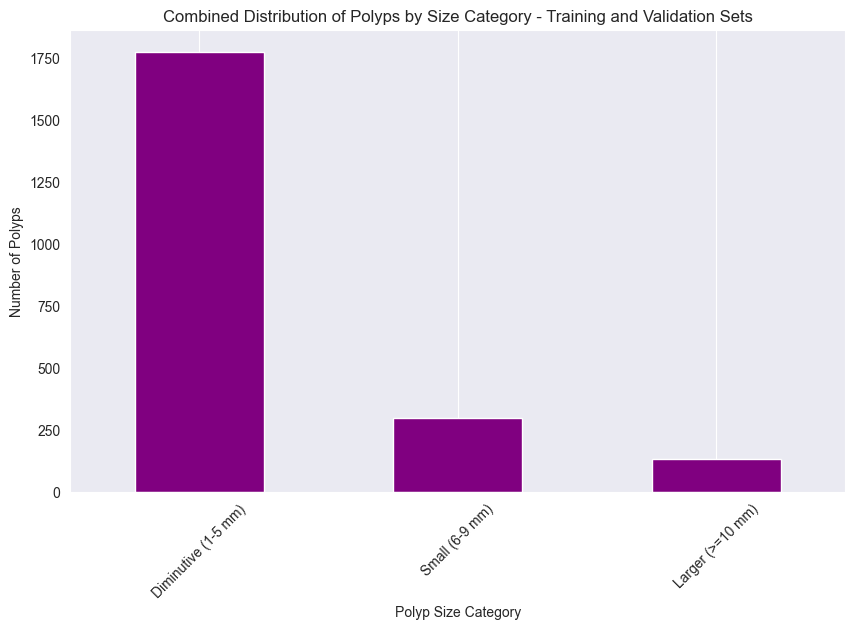

In [15]:
# Combine the size category distributions from both the training and validation sets
size_category_distribution_combined_all = pd.concat([size_categories_train, size_categories_validation]).value_counts().sort_index()

print(size_category_distribution_combined_all)

# Generate a bar chart for the combined distribution of polyp sizes
size_category_distribution_combined_all.plot(kind='bar', figsize=(10, 6), color='purple')
plt.title('Combined Distribution of Polyps by Size Category - Training and Validation Sets')
plt.xlabel('Polyp Size Category')
plt.ylabel('Number of Polyps')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()

In [ ]:
# Distribution by pathology diagnosis

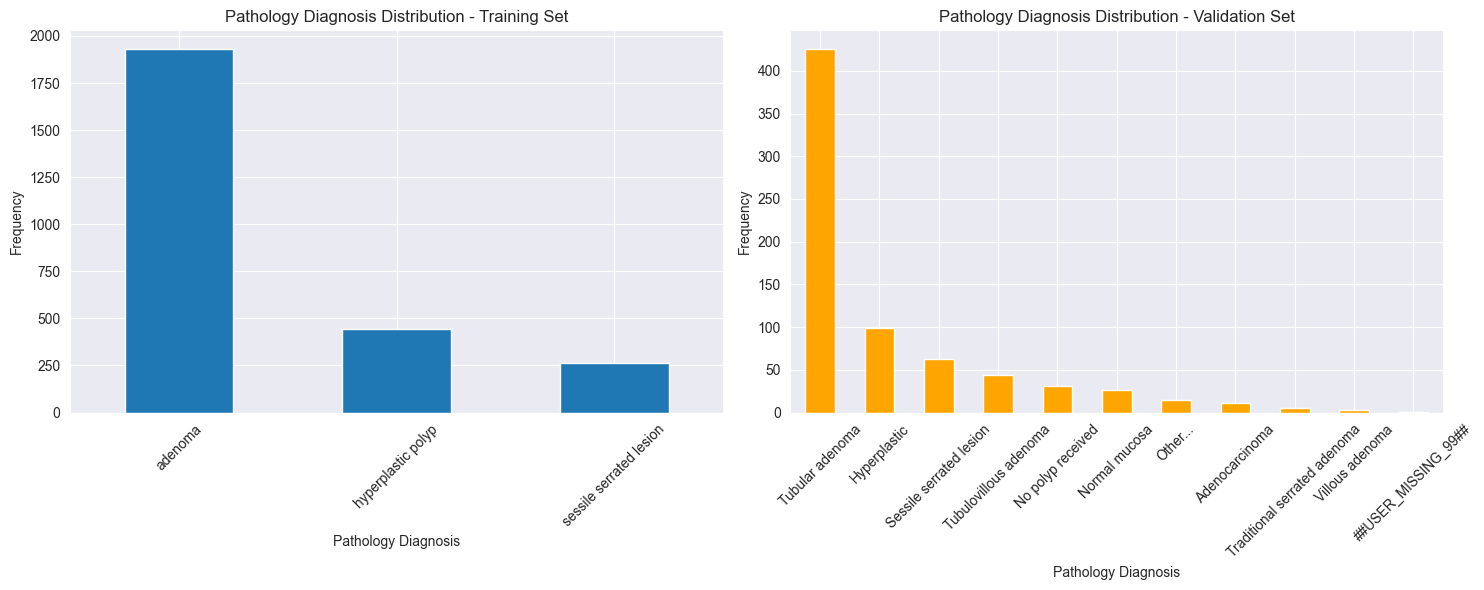

(PATHOLOGY DIAGNOSIS
 adenoma                    1933
 hyperplastic polyp          443
 sessile serrated lesion     261
 Name: count, dtype: int64,
 PATHOLOGY DIAGNOSIS
 Tubular adenoma                 426
 Hyperplastic                     99
 Sessile serrated lesion          63
 Tubulovillous adenoma            44
 No polyp received                31
 Normal mucosa                    26
 Other...                         15
 Adenocarcinoma                   11
 Traditional serrated adenoma      5
 Villous adenoma                   3
 ##USER_MISSING_99##               1
 Name: count, dtype: int64)

In [16]:
# Calculate the distribution of polyps by pathology diagnosis for both sets
pathology_distribution_train = train_set['PATHOLOGY DIAGNOSIS'].value_counts()
pathology_distribution_validation = validation_set['PATHOLOGY DIAGNOSIS'].value_counts()

# Generate histograms for the distribution of polyps by pathology diagnosis
plt.figure(figsize=(15, 6))

# Histogram for the training set
plt.subplot(1, 2, 1)
pathology_distribution_train.plot(kind='bar')
plt.title('Pathology Diagnosis Distribution - Training Set')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)

# Histogram for the validation set
plt.subplot(1, 2, 2)
pathology_distribution_validation.plot(kind='bar', color='orange')
plt.title('Pathology Diagnosis Distribution - Validation Set')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

pathology_distribution_train, pathology_distribution_validation

In [ ]:
# Distribution by pathology diagnosis. Train and validation sets together

/var/folders/09/7_lhn8c12k90ktfsdlxf2nsh0000gn/T/ipykernel_17179/3739047541.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  validation_set_filtered_cleaned = validation_set_filtered[validation_set['PATHOLOGY DIAGNOSIS'] != '##USER_MISSING_99##']


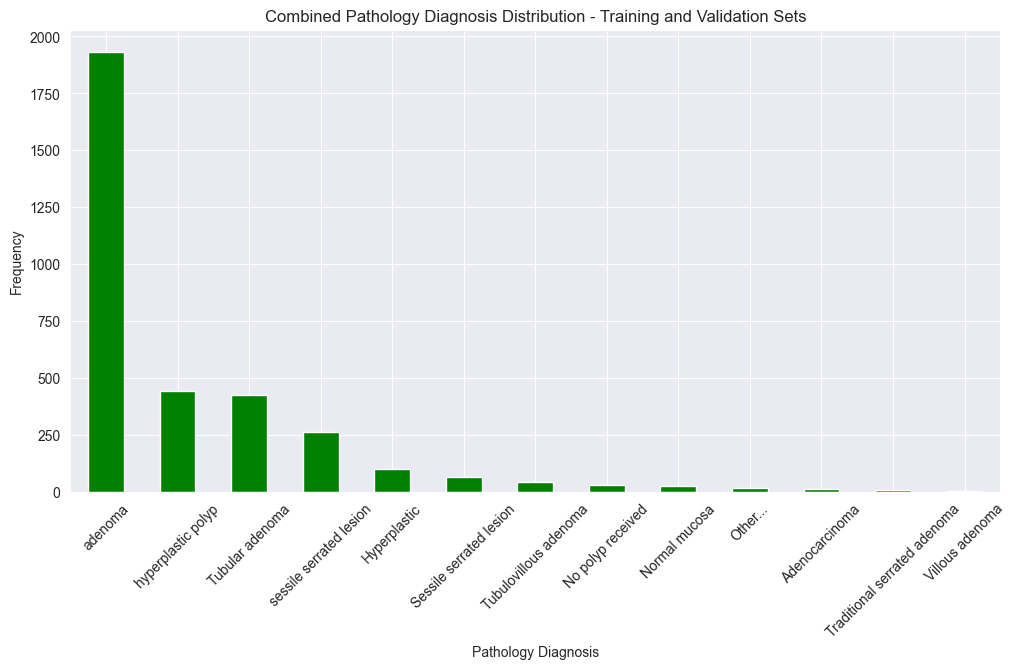

PATHOLOGY DIAGNOSIS
adenoma                         1933
hyperplastic polyp               443
Tubular adenoma                  425
sessile serrated lesion          261
Hyperplastic                      99
Sessile serrated lesion           63
Tubulovillous adenoma             44
No polyp received                 31
Normal mucosa                     26
Other...                          15
Adenocarcinoma                    10
Traditional serrated adenoma       5
Villous adenoma                    3
Name: count, dtype: int64

In [17]:
# Remove the entry with '##USER_MISSING_99##' from the validation set for combined analysis
validation_set_filtered_cleaned = validation_set_filtered[validation_set['PATHOLOGY DIAGNOSIS'] != '##USER_MISSING_99##']

# Combine the pathology diagnosis data from both sets
combined_pathology = pd.concat([train_set['PATHOLOGY DIAGNOSIS'], validation_set_filtered_cleaned['PATHOLOGY DIAGNOSIS']])

# Calculate the combined distribution of polyps by pathology diagnosis
combined_pathology_distribution = combined_pathology.value_counts()

# Generate a histogram for the combined distribution
plt.figure(figsize=(12, 6))
combined_pathology_distribution.plot(kind='bar', color='green')
plt.title('Combined Pathology Diagnosis Distribution - Training and Validation Sets')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

combined_pathology_distribution

In [ ]:
# Distribution of polyps per patient. Train and validations sets analyzed separately

POLYP_ID
1      19
2     184
3      40
4     112
5      20
6      68
7      23
8      27
9       7
10     19
11      5
12      9
13      3
14      4
15      3
16      2
17      1
18      1
20      3
21      3
23      1
28      1
Name: count, dtype: int64 POLYP/IMAGE_ID
1     75
2     54
3     47
4     34
5     13
6     10
7      9
8      5
9      1
10     2
13     1
Name: count, dtype: int64 count    555.000000
mean       4.751351
std        3.673421
min        1.000000
25%        2.000000
50%        4.000000
75%        6.000000
max       28.000000
Name: POLYP_ID, dtype: float64 count    251.000000
mean       2.908367
std        2.030657
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       13.000000
Name: POLYP/IMAGE_ID, dtype: float64


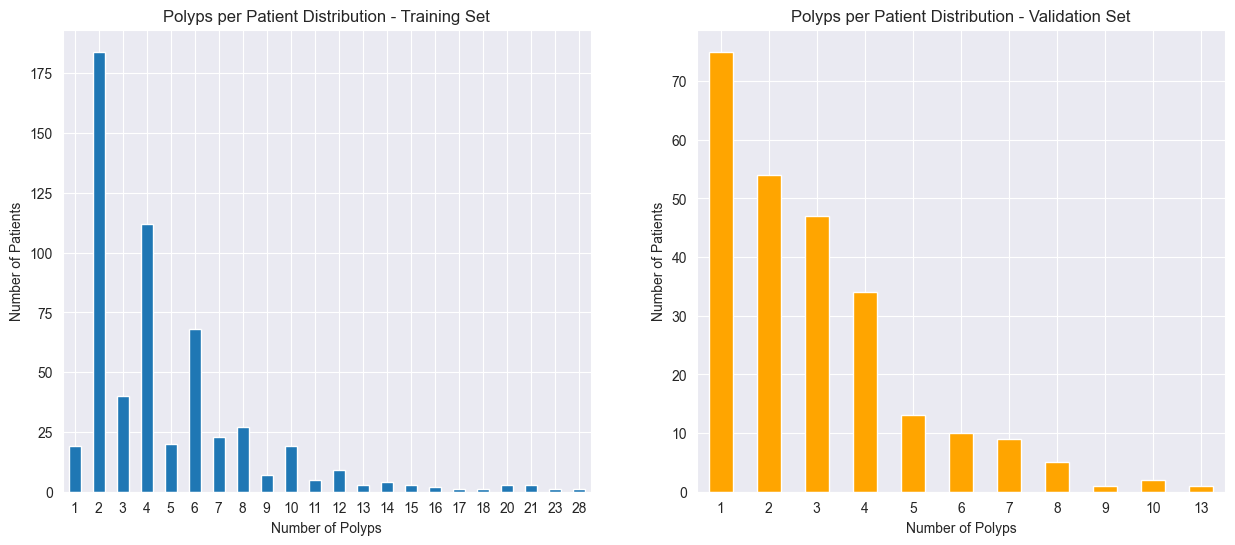

<Figure size 800x600 with 0 Axes>

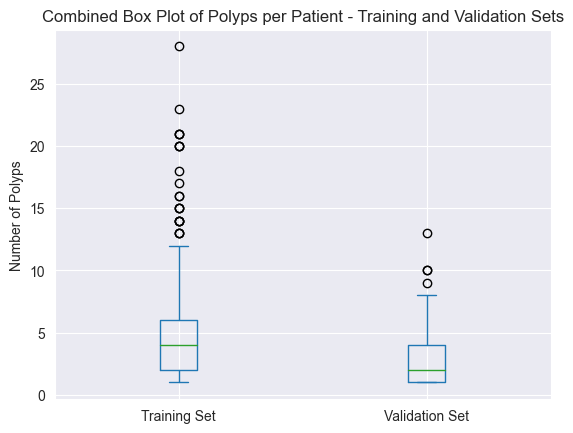

In [18]:
# Calculate the distribution of polyps per patient for the original (unfiltered) training and validation sets
polyps_per_patient_train_original = train_set.groupby('PATIENT_ID')['POLYP_ID'].count()
polyps_per_patient_train_distribution_original = polyps_per_patient_train_original.value_counts().sort_index()

polyps_per_patient_validation_original = validation_set.groupby('PATIENT_ID')['POLYP/IMAGE_ID'].count()
polyps_per_patient_validation_distribution_original = polyps_per_patient_validation_original.value_counts().sort_index()

# Calculate the descriptive statistics for the number of polyps per patient in the original sets
desc_stats_polyps_per_patient_train_original = polyps_per_patient_train_original.describe()
desc_stats_polyps_per_patient_validation_original = polyps_per_patient_validation_original.describe()

print (polyps_per_patient_train_distribution_original, polyps_per_patient_validation_distribution_original, desc_stats_polyps_per_patient_train_original, desc_stats_polyps_per_patient_validation_original)

# Generate histograms for the revised distribution of polyps per patient
plt.figure(figsize=(15, 6))

# Histogram for the training set
plt.subplot(1, 2, 1)
polyps_per_patient_train_distribution_original.plot(kind='bar')
plt.title('Polyps per Patient Distribution - Training Set')
plt.xlabel('Number of Polyps')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)

# Histogram for the validation set
plt.subplot(1, 2, 2)
polyps_per_patient_validation_distribution_original.plot(kind='bar', color='orange')
plt.title('Polyps per Patient Distribution - Validation Set')
plt.xlabel('Number of Polyps')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.show()

# Combine both training and validation sets into one DataFrame for a combined box plot
combined_polyps_per_patient = pd.DataFrame({
    'Training Set': polyps_per_patient_train_original,
    'Validation Set': polyps_per_patient_validation_original
})

# Generate a combined box plot for both sets
plt.figure(figsize=(8, 6))
combined_polyps_per_patient.plot(kind='box')
plt.title('Combined Box Plot of Polyps per Patient - Training and Validation Sets')
plt.ylabel('Number of Polyps')
plt.grid(True)
plt.show()


In [ ]:
# Distribution of polyps per patient. Train and validations sets analyzed together

count    806.000000
mean       4.177419
std        3.361017
min        1.000000
25%        2.000000
50%        3.000000
75%        6.000000
max       28.000000
dtype: float64


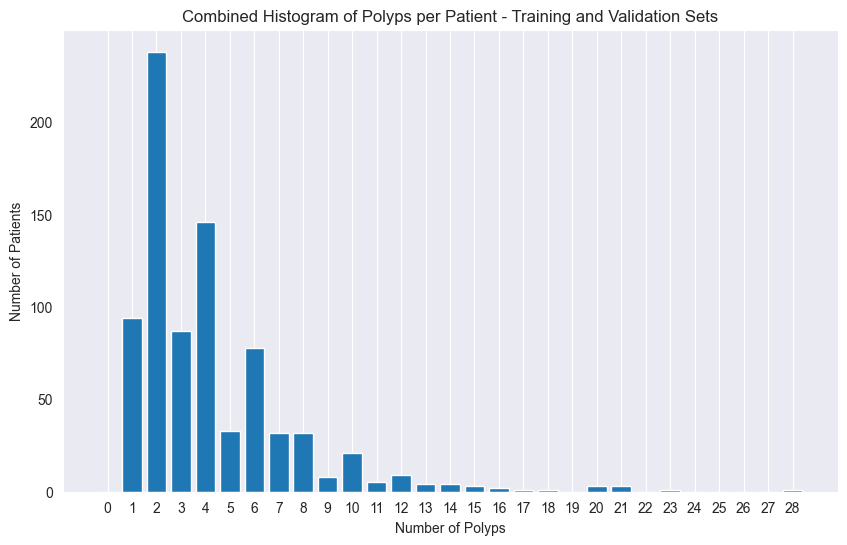

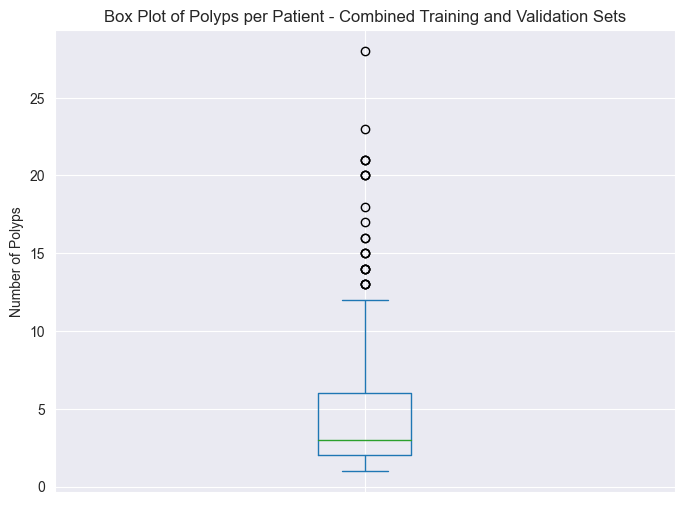

In [19]:
# Combine the polyp count per patient data from both sets for a combined distribution analysis
combined_polyps_per_patient_all = pd.concat([polyps_per_patient_train_original, polyps_per_patient_validation_original])

# Generate the descriptive statistics for the combined data
desc_stats_combined_polyps_per_patient = combined_polyps_per_patient_all.describe()

print(desc_stats_combined_polyps_per_patient)

# Generate a histogram for the combined distribution of polyps per patient
plt.figure(figsize=(10, 6))
combined_polyps_per_patient_all.hist(bins=range(int(combined_polyps_per_patient_all.max()) + 2), rwidth=0.8, align='left')
plt.title('Combined Histogram of Polyps per Patient - Training and Validation Sets')
plt.xlabel('Number of Polyps')
plt.ylabel('Number of Patients')
plt.grid(axis='y')
plt.xticks(range(int(combined_polyps_per_patient_all.max()) + 1))
plt.show()

# Generate a box plot for the combined distribution of polyps per patient across both sets
plt.figure(figsize=(8, 6))
combined_polyps_per_patient_all.plot(kind='box', vert=True)
plt.title('Box Plot of Polyps per Patient - Combined Training and Validation Sets')
plt.ylabel('Number of Polyps')
plt.grid(True)
plt.show()


In [ ]:
# Location analysis. Descriptive statistics

In [20]:
# Function to parse the polyp position and extract x and y coordinates
def extract_coordinates(positions):
    coordinates = positions.str.strip('[]').str.split(',', expand=True).astype(int)
    x = coordinates[0]
    y = coordinates[1]
    return x, y

# Extract coordinates for the training set
x_train_original, y_train_original = extract_coordinates(train_set['POLYP POSITION (x,y,w,h)'])

# Extract coordinates for the validation set
x_validation_original, y_validation_original = extract_coordinates(validation_set['POLYP POSITION (x,y,w,h)'])

# Generate descriptive statistics for the polyp positions in both sets using the original coordinates
desc_stats_positions_train_original = pd.concat([x_train_original, y_train_original], axis=1).describe()
desc_stats_positions_validation_original = pd.concat([x_validation_original, y_validation_original], axis=1).describe()

desc_stats_positions_train_original, desc_stats_positions_validation_original

(                 0            1
 count  2637.000000  2637.000000
 mean    547.997725   362.005688
 std     300.969733   186.486770
 min     -14.000000   -36.000000
 25%     337.000000   228.000000
 50%     499.000000   353.000000
 75%     719.000000   485.000000
 max    1601.000000   973.000000,
                  0           1
 count   730.000000  730.000000
 mean    460.783562  359.386301
 std     243.742803  193.370612
 min       0.000000    0.000000
 25%     288.500000  232.250000
 50%     451.500000  355.000000
 75%     617.000000  502.000000
 max    1442.000000  892.000000)

In [ ]:
# We filter out those entries where any of the coordinates is negative

In [21]:
# Function to check for negative values in the position data
def has_negative_values(position):
    coordinates = position.strip('[]').split(',')
    return any(int(coord) < 0 for coord in coordinates)

# Filter out entries with negative coordinates in both sets
train_set_filtered_positive = train_set[~train_set['POLYP POSITION (x,y,w,h)'].apply(has_negative_values)]
validation_set_filtered_positive = validation_set[~validation_set['POLYP POSITION (x,y,w,h)'].apply(has_negative_values)]

# Extract coordinates for the positively filtered datasets
x_train_positive, y_train_positive = extract_coordinates(train_set_filtered_positive['POLYP POSITION (x,y,w,h)'])
x_validation_positive, y_validation_positive = extract_coordinates(validation_set_filtered_positive['POLYP POSITION (x,y,w,h)'])

# Generate descriptive statistics for the polyp positions in the positively filtered sets
desc_stats_positions_train_positive = pd.concat([x_train_positive, y_train_positive], axis=1).describe()
desc_stats_positions_validation_positive = pd.concat([x_validation_positive, y_validation_positive], axis=1).describe()

desc_stats_positions_train_positive, desc_stats_positions_validation_positive

(                 0            1
 count  2597.000000  2597.000000
 mean    552.043512   367.266846
 std     300.470356   182.626173
 min       0.000000     0.000000
 25%     340.000000   233.000000
 50%     502.000000   358.000000
 75%     723.000000   489.000000
 max    1601.000000   973.000000,
                  0           1
 count   730.000000  730.000000
 mean    460.783562  359.386301
 std     243.742803  193.370612
 min       0.000000    0.000000
 25%     288.500000  232.250000
 50%     451.500000  355.000000
 75%     617.000000  502.000000
 max    1442.000000  892.000000)

In [ ]:
# We identify the entries with negative coordinate values

In [22]:
# Identifying the entries with negative coordinates in both sets
negative_coords_train = train_set[train_set['POLYP POSITION (x,y,w,h)'].apply(has_negative_values)]
negative_coords_validation = validation_set[validation_set['POLYP POSITION (x,y,w,h)'].apply(has_negative_values)]

# Displaying the entries with negative coordinates along with Patient ID
negative_coords_train[['PATIENT_ID', 'POLYP_ID', 'IMG_FILE_PREFIX', 'POLYP POSITION (x,y,w,h)']]

,PATIENT_ID,POLYP_ID,IMG_FILE_PREFIX,"POLYP POSITION (x,y,w,h)"
8,2092490df624877b6963f7a0afb7ba76,5524a665e549a32e3b581180ff34a71d,3ab26075-940f-4f85-b9b1-b32582f2fd83,"[-7, 341, 707, 536]"
9,2092490df624877b6963f7a0afb7ba76,5524a665e549a32e3b581180ff34a71d,9987fe72-9e7d-4a16-b913-1c9caa543cb6,"[-14, 266, 1083, 621]"
89,3ed19b740fe7d4a76d7cc85e8cd537f2,7f9edf55dd16535ef3d68dc2d6e22854,d32dc548-6508-4fba-95e1-238de0f28c3a,"[33, -32, 961, 795]"
149,f9b4a4510d6d99cc6fc4fb85c99d2155,30eb990c1b12175f7b36850f98b94186,ab46f03e-4d00-46f4-b560-14a1a50bc7e1,"[422, -2, 314, 291]"
375,831d36ed88117690a2eaba1ef31fedc6,c3f374af54836f4f42c43541b52e0e7b,ab7c3e62-cd12-4991-9818-79bec0f315b1,"[400, -5, 579, 530]"
411,9aa6dc92b218e8c68a0443707cbed5c1,cc6218aeb9cfb32b0446efae242d4e22,f3a9df88-43f4-478b-ae69-31a35a9ccd05,"[644, -10, 390, 704]"
507,fd1e6dc76541fec542463d79cd53eead,3e2fe9a95901df0ee526011e88f9ce1a,6621092e-690c-441f-b734-224af6c1b766,"[47, -18, 598, 603]"
675,52e77edee98c96f9642b7fc46ac2fc7b,e8c98848c0bbea077b7950a00ba6e9df,40b7a638-7dc9-4642-a5f2-a3d227a70122,"[272, -32, 682, 718]"
850,289e1c8836044ee7e2129a938d0ea79c,08b7f781b6e8463af4a815738dd34d18,476000d7-d14f-4eba-8d30-7a2156c0f8d0,"[221, -33, 762, 651]"
880,0a87a6ac7f01fb4182558fc54f5e3405,4b84a41d09159c054b21f292ea05de03,ec99f7bc-6b66-43fa-a159-3cee17e48976,"[-13, 134, 723, 747]"


In [ ]:
# Let's analyze visually what happens with images in the train set that have negative coordinates

In [26]:
def draw_bounding_box(image_path, position, save_path):
    # Load the image
    image = Image.open(image_path)
    
    # Parse the position and correct negative values
    x, y, w, h = np.maximum([int(num) for num in position.strip('[]').split(',')], 0)

    # Start the plot
    fig, ax = plt.subplots()
    ax.imshow(image)

    # Create a Rectangle patch for the bounding box and add it to the plot
    rect = patches.Rectangle((x, y), w, h, linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

    # Remove axes
    plt.axis('off')

    # Save the figure
    plt.savefig(save_path, bbox_inches='tight', pad_inches=0)
    plt.close()


output_image_path = filedialog.askdirectory(title="Select Image Output Folder")

# Assuming negative_coords_train is a DataFrame with the necessary columns
for index, row in negative_coords_train.iterrows():
    position = row['POLYP POSITION (x,y,w,h)']
    img_prefix = row['IMG_FILE_PREFIX']
    
    patient_folder = os.path.join(train_folder_path, row['PATIENT_ID'])
    polyp_folder = os.path.join(patient_folder, row['POLYP_ID'])
    image_file_path = os.path.join(polyp_folder, img_prefix + ".full.png")
    
    # If the image file exists, draw the bounding box and save the new image
    if os.path.exists(image_file_path):
        new_image_path = os.path.join(output_image_path, f"{img_prefix}_bbox.png")
        draw_bounding_box(image_file_path, position, new_image_path)


In [ ]:
# Replacing negative coordinate values with "0" seems to be safe 

In [23]:
# Function to replace negative coordinates with zero and return a cleaned position string
def clean_position(position):
    # Split the position string into a list of integers
    coords = [int(coord) for coord in position.strip('[]').split(',')]
    # Replace negative coordinates with zero
    cleaned_coords = [max(coord, 0) for coord in coords]
    # Convert the list of integers back into the original string format
    return str(cleaned_coords)

# Apply the cleaning function to both training and validation sets
train_set['POLYP POSITION (x,y,w,h)'] = train_set['POLYP POSITION (x,y,w,h)'].apply(clean_position)
validation_set['POLYP POSITION (x,y,w,h)'] = validation_set['POLYP POSITION (x,y,w,h)'].apply(clean_position)

 # Save the updated spreadsheets
no_negative_suffix = "no-negative-coords"
spreadsheet_no_negative_coords = spreadsheet_with_image_properties_path.replace('.xlsx', f'_{no_negative_suffix}.xlsx')
with pd.ExcelWriter(spreadsheet_no_negative_coords) as writer:
    train_set.to_excel(writer, sheet_name='train_set', index=False)
    validation_set.to_excel(writer, sheet_name='validation_set', index=False)

print(f"Updated spreadsheet saved as {spreadsheet_no_negative_coords}")

Updated spreadsheet saved as /Users/irconde/Downloads/Databases/POLAR/polar_public/polar_annotations_20231125192143_no-negative-coords.xlsx


In [ ]:
# Location analysis. Heat-map-based representation

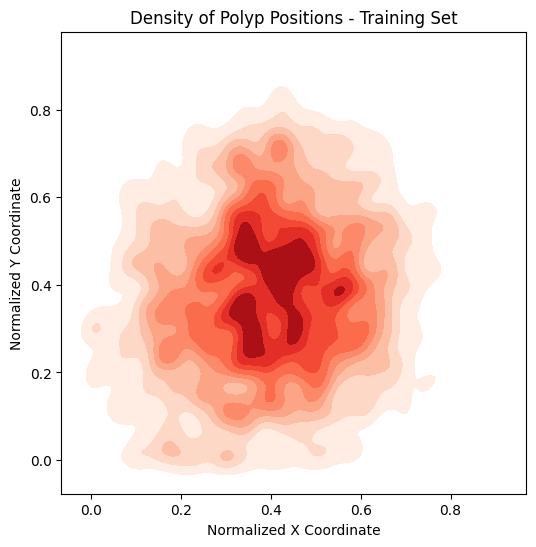

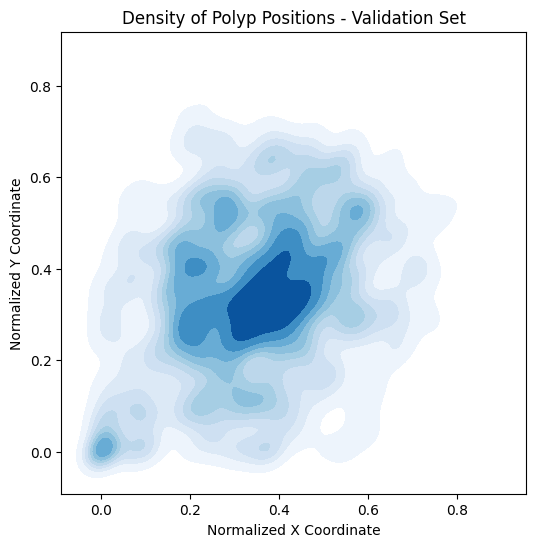

In [24]:
import seaborn as sns

# Function to parse the polyp position and extract normalized x and y coordinates
def extract_normalized_coordinates(positions, image_width, image_height):
    coordinates = positions.str.strip('[]').str.split(',', expand=True).astype(int)
    normalized_x = coordinates[0] / image_width
    normalized_y = coordinates[1] / image_height
    return normalized_x, normalized_y

# Extract and normalize coordinates for the training set
x_train, y_train = extract_normalized_coordinates(train_set['POLYP POSITION (x,y,w,h)'], train_set['Width'], train_set['Height'])


# Plotting the density of polyp positions for the training set
plt.figure(figsize=(6, 6))
sns.kdeplot(x=x_train, y=y_train, cmap="Reds", fill=True, bw_adjust=0.5)
plt.title('Density of Polyp Positions - Training Set')
plt.xlabel('Normalized X Coordinate')
plt.ylabel('Normalized Y Coordinate')
plt.show()

# Extract and normalize coordinates for the validation set
x_validation, y_validation = extract_normalized_coordinates(validation_set['POLYP POSITION (x,y,w,h)'], validation_set['Width'], validation_set['Height'])

# Plotting the density of polyp positions for the validation set
plt.figure(figsize=(6, 6))
sns.kdeplot(x=x_validation, y=y_validation, cmap="Blues", fill=True, bw_adjust=0.5)
plt.title('Density of Polyp Positions - Validation Set')
plt.xlabel('Normalized X Coordinate')
plt.ylabel('Normalized Y Coordinate')
plt.show()


In [ ]:
# Location analysis. Are there bounding boxes that exceed the boundaries of the images? 

In [24]:
def check_boundary_exceedance(df):
    """
    Function to check if the polyp locations exceed the image boundaries.
    """
    # Extracting polyp positions and converting them to numeric values
    df['x'], df['y'], df['w'], df['h'] = zip(*df['POLYP POSITION (x,y,w,h)'].apply(lambda x: eval(x)))

    # Checking if the polyp locations exceed the image boundaries
    df['Exceeds_Width'] = (df['x'] + df['w']) > df['Width']
    df['Exceeds_Height'] = (df['y'] + df['h']) > df['Height']

    # Returning rows where either width or height is exceeded
    return df[(df['Exceeds_Width']) | (df['Exceeds_Height'])]

def update_boundary_exceedance_reason(df):
    """
    Update the boundary exceedance reason to handle cases where both width and height are exceeded.
    """
    def determine_exceedance_reason(row):
        if row['Exceeds_Width'] and row['Exceeds_Height']:
            return 'Width & Height'
        elif row['Exceeds_Width']:
            return 'Width'
        elif row['Exceeds_Height']:
            return 'Height'
        else:
            return 'None'

    df['Boundary Exceedance'] = df.apply(determine_exceedance_reason, axis=1)
    return df

# Checking for boundary exceedance in both train and validation sets
exceedance_train = check_boundary_exceedance(train_set.copy())
exceedance_validation = check_boundary_exceedance(validation_set.copy())

# For Train Set
exceedance_train_updated = update_boundary_exceedance_reason(exceedance_train.copy())
exceedance_train_list = exceedance_train_updated[['PATIENT_ID', 'POLYP_ID', 'IMG_FILE_PREFIX', 'POLYP POSITION (x,y,w,h)', 'Width', 'Height', 'Boundary Exceedance']].copy()
exceedance_train_list['Set'] = 'Train Set'

# For Validation Set
exceedance_validation_updated = update_boundary_exceedance_reason(exceedance_validation.copy())
exceedance_validation_list = exceedance_validation_updated[['PATIENT_ID', 'POLYP/IMAGE_ID', 'POLYP POSITION (x,y,w,h)', 'Width', 'Height', 'Boundary Exceedance']].copy()
exceedance_validation_list['Set'] = 'Validation Set'

# Renaming column for consistency in Validation Set
exceedance_validation_list.rename(columns={'POLYP/IMAGE_ID': 'POLYP_ID'}, inplace=True)

# Combining the lists
combined_exceedance_list = pd.concat([exceedance_train_list, exceedance_validation_list], ignore_index=True)

combined_exceedance_list


,PATIENT_ID,POLYP_ID,IMG_FILE_PREFIX,"POLYP POSITION (x,y,w,h)",Width,Height,Boundary Exceedance,Set
0,2092490df624877b6963f7a0afb7ba76,c48bb221b3559bdf5726b1c269996161,f5cfdfb1-e731-4da0-b0e1-205597621b2f,"[575, 770, 295, 104]",1096,864,Height,Train Set
1,2092490df624877b6963f7a0afb7ba76,5524a665e549a32e3b581180ff34a71d,3ab26075-940f-4f85-b9b1-b32582f2fd83,"[0, 341, 707, 536]",1096,864,Height,Train Set
2,2092490df624877b6963f7a0afb7ba76,5524a665e549a32e3b581180ff34a71d,9987fe72-9e7d-4a16-b913-1c9caa543cb6,"[0, 266, 1083, 621]",1096,864,Height,Train Set
3,23400ef9b6864b6d85415676c0dfe55e,49e14d5eb56eb6b326105d1841db5da0,9852c7f7-62d1-4d05-ac73-6149e2900ca0,"[112, 502, 705, 375]",1096,864,Height,Train Set
4,23400ef9b6864b6d85415676c0dfe55e,49e14d5eb56eb6b326105d1841db5da0,cb332650-26eb-4ffa-b5db-87dd83c892d7,"[138, 518, 726, 370]",1096,864,Height,Train Set
...,...,...,...,...,...,...,...,...
121,33389365643facf706a81d21945018c8,ab829cf8e877e35d12589eb246405ef9,6e29c9fe-6a5d-4500-b1f5-fbf256606738,"[93, 205, 794, 680]",1096,864,Height,Train Set
122,33389365643facf706a81d21945018c8,ab829cf8e877e35d12589eb246405ef9,f88b8608-cd17-4bb4-ac5e-63641b0b7d74,"[111, 285, 695, 607]",1096,864,Height,Train Set
123,fb7ebd2170fa313a034fbe1fdf1a032d,067adc3cb17d84677c10c1e03bc5fb77,6e0e3bdd-2ac2-4797-92c7-e63833cd5e33,"[589, 752, 154, 131]",1096,864,Height,Train Set
124,55dac536cf9f10af9299eed3deb64efb,c3434f07e2d52c50333ee2c5bec3cea2,75aead51-81e1-4c53-977f-34bf1b823d79,"[694, 643, 328, 235]",1096,864,Height,Train Set


In [ ]:
# Let's analyze visually what happens with those images

In [28]:
output_image_path = filedialog.askdirectory(title="Select Image Output Folder")

# For the train set
for index, row in combined_exceedance_list.iterrows():
    
    set = row['Set']
    position = row['POLYP POSITION (x,y,w,h)']
    if set == 'Train Set':
        img_prefix = row['IMG_FILE_PREFIX']
        patient_folder = os.path.join(train_folder_path, row['PATIENT_ID'])
        polyp_folder = os.path.join(patient_folder, row['POLYP_ID'])
    else:
        img_prefix = row['POLYP_ID']
        polyp_folder = os.path.join(validation_folder_path, row['PATIENT_ID'])
    
    image_file_path = os.path.join(polyp_folder, img_prefix + ".full.png")
    
    # If the image file exists, draw the bounding box and save the new image
    if os.path.exists(image_file_path):
        new_image_path = os.path.join(output_image_path, f"{img_prefix}_bbox.png")
        draw_bounding_box(image_file_path, position, new_image_path)


In [ ]:
# We need to calculate the maximum value for these coordinates to fix this issue

In [29]:
def adjust_polyp_dimensions_override(df):
    """
    Adjust the width or height of the polyp position if they exceed the image boundaries and override the original values.
    """
    # Extracting polyp positions and converting them to numeric values
    df['x'], df['y'], df['w'], df['h'] = zip(*df['POLYP POSITION (x,y,w,h)'].apply(lambda x: eval(x)))

    # Adjusting width and height if they exceed image boundaries
    df['w'] = df.apply(lambda row: min(row['w'], row['Width'] - row['x']), axis=1)
    df['h'] = df.apply(lambda row: min(row['h'], row['Height'] - row['y']), axis=1)

    # Updating the POLYP POSITION column with the adjusted values
    df['POLYP POSITION (x,y,w,h)'] = df.apply(lambda row: f"[{row['x']}, {row['y']}, {row['w']}, {row['h']}]", axis=1)

    return df

# Applying the function to both train and validation sets
train_set_adjusted_override = adjust_polyp_dimensions_override(train_set.copy())
validation_set_adjusted_override = adjust_polyp_dimensions_override(validation_set.copy())

 # Save the updated spreadsheets
no_exceeding_coords_suffix = "no-exceeding-coords"
spreadsheet_no_negative_coords = spreadsheet_no_negative_coords.replace('.xlsx', f'_{no_exceeding_coords_suffix}.xlsx')
with pd.ExcelWriter(spreadsheet_no_negative_coords) as writer:
    train_set_adjusted_override.to_excel(writer, sheet_name='train_set', index=False)
    validation_set_adjusted_override.to_excel(writer, sheet_name='validation_set', index=False)

print(f"Updated spreadsheet saved as {spreadsheet_no_negative_coords}")


Updated spreadsheet saved as /Users/irconde/Downloads/Databases/POLAR/polar_public/polar_annotations_20231125192143_no-negative-coords_no-exceeding-coords.xlsx


In [30]:
# Checking for boundary exceedance in both train and validation sets
exceedance_train = check_boundary_exceedance(train_set_adjusted_override.copy())
exceedance_validation = check_boundary_exceedance(validation_set_adjusted_override.copy())

# For Train Set
exceedance_train_updated = update_boundary_exceedance_reason(exceedance_train.copy())
exceedance_train_list = exceedance_train_updated[['PATIENT_ID', 'POLYP_ID', 'IMG_FILE_PREFIX', 'POLYP POSITION (x,y,w,h)', 'Width', 'Height', 'Boundary Exceedance']].copy()
exceedance_train_list['Set'] = 'Train Set'

# For Validation Set
exceedance_validation_updated = update_boundary_exceedance_reason(exceedance_validation.copy())
exceedance_validation_list = exceedance_validation_updated[['PATIENT_ID', 'POLYP/IMAGE_ID', 'POLYP POSITION (x,y,w,h)', 'Width', 'Height', 'Boundary Exceedance']].copy()
exceedance_validation_list['Set'] = 'Validation Set'

# Renaming column for consistency in Validation Set
exceedance_validation_list.rename(columns={'POLYP/IMAGE_ID': 'POLYP_ID'}, inplace=True)

# Combining the lists
combined_exceedance_list = pd.concat([exceedance_train_list, exceedance_validation_list], ignore_index=True)

combined_exceedance_list

,PATIENT_ID,POLYP_ID,IMG_FILE_PREFIX,"POLYP POSITION (x,y,w,h)",Width,Height,Boundary Exceedance,Set
